# AI4I 2020 Predictive Maintenance — Exploratory Data Analysis
**DS 301 Midterm Project**

This notebook explores the raw dataset to understand its structure, data quality, class balance, and how sensor readings relate to machine failure. The findings motivate the steps in `preprocess.py`.

Run from the repository root, with the dataset at `data/raw/ai4i2020.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RAW_PATH = "data/raw/ai4i2020.csv"
TARGET = "Machine failure"
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NUM_COLS = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

df = pd.read_csv(RAW_PATH)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Dataset overview

In [2]:
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
df.info()

Rows: 10,000  |  Columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: fl

Column roles:
- **Identifiers**: `UDI` (row number), `Product ID` (serial number) → no predictive value
- **Categorical**: `Type` — product quality variant (L / M / H)
- **Sensor features**: air/process temperature, rotational speed, torque, tool wear
- **Target**: `Machine failure` (0/1)
- **Failure modes**: `TWF`, `HDF`, `PWF`, `OSF`, `RNF` — sub-types of the target (leakage if used as features)

## 2. Data quality

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate Product IDs: {df['Product ID'].duplicated().sum()}")
quality

Duplicate rows: 0
Duplicate Product IDs: 0


,dtype,missing,unique
UDI,int64,0,10000
Product ID,str,0,10000
Type,str,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


In [4]:
df[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


No missing values or duplicates, and all sensor ranges are physically plausible. No imputation or row removal is needed.

## 3. Target distribution (class imbalance)

Machine failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39%


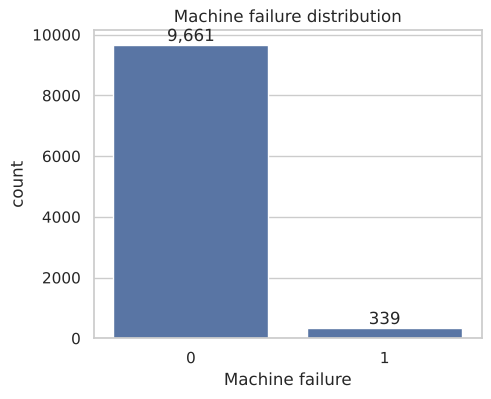

In [5]:
counts = df[TARGET].value_counts()
print(counts)
print(f"Failure rate: {df[TARGET].mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Machine failure distribution")
plt.show()

Only about **3.4%** of samples are failures. A model that always predicts "no failure" would get ~96.6% accuracy, so we should evaluate with **F1, recall, precision, and PR-AUC**, use a **stratified** train/test split, and consider class weights or oversampling (training set only).

## 4. Failure modes

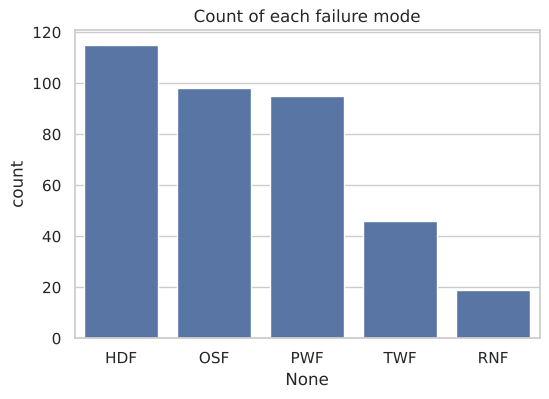

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [6]:
mode_counts = df[FAILURE_MODES].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=mode_counts.index, y=mode_counts.values, ax=ax)
ax.set_title("Count of each failure mode")
ax.set_ylabel("count")
plt.show()
mode_counts

In [7]:
n_modes = df[FAILURE_MODES].sum(axis=1)
pd.crosstab(df[TARGET], n_modes, rownames=["Machine failure"], colnames=["# failure modes"])

# failure modes,0,1,2,3
Machine failure,,,,
0,9643,18,0,0
1,9,306,23,1


In [8]:
mismatch_a = df[(df[TARGET] == 0) & (n_modes > 0)]
mismatch_b = df[(df[TARGET] == 1) & (n_modes == 0)]
print(f"Failure mode present but Machine failure = 0: {len(mismatch_a)} rows")
print(mismatch_a[FAILURE_MODES].sum())
print(f"\nMachine failure = 1 but no failure mode: {len(mismatch_b)} rows")

Failure mode present but Machine failure = 0: 18 rows
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64

Machine failure = 1 but no failure mode: 9 rows


- Some failures have **more than one** mode at once.
- **Label inconsistencies:** 18 rows have a failure mode but `Machine failure = 0` (all are RNF), and 9 rows have `Machine failure = 1` with no mode recorded. The team should decide whether to keep or drop them, following the paper we are reproducing.
- Because the failure modes define the target, they are **dropped from the features** in preprocessing.

## 5. Product type vs. failure

      count  failures  failure_rate
Type                               
L      6000       235      0.039167
M      2997        83      0.027694
H      1003        21      0.020937


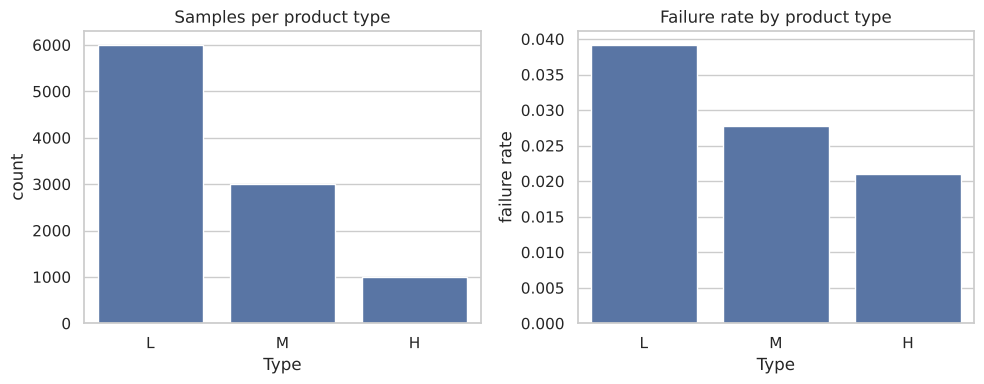

In [9]:
type_summary = df.groupby("Type")[TARGET].agg(count="size", failures="sum", failure_rate="mean")
type_summary = type_summary.loc[["L", "M", "H"]]
print(type_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Type", data=df, order=["L", "M", "H"], ax=axes[0])
axes[0].set_title("Samples per product type")
sns.barplot(x=type_summary.index, y=type_summary["failure_rate"], ax=axes[1])
axes[1].set_title("Failure rate by product type")
axes[1].set_ylabel("failure rate")
plt.tight_layout()
plt.show()

Low-quality (L) products are the majority (60%) and fail somewhat more often. Since L < M < H has a natural order, `Type` is ordinal-encoded (L=0, M=1, H=2).

## 6. Sensor feature distributions

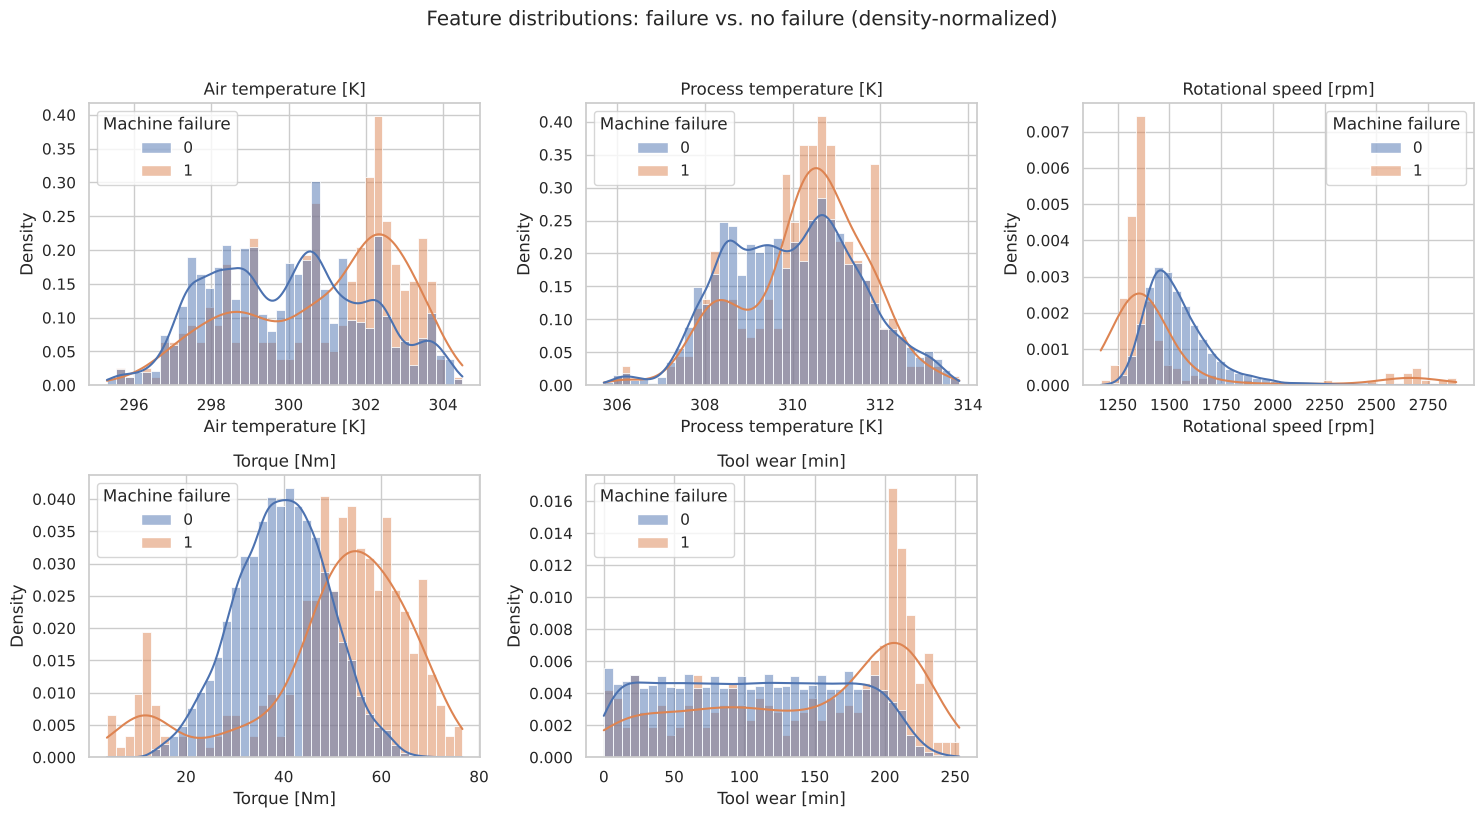

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.histplot(data=df, x=col, hue=TARGET, stat="density", common_norm=False,
                 bins=40, kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Feature distributions: failure vs. no failure (density-normalized)", y=1.02)
plt.tight_layout()
plt.show()

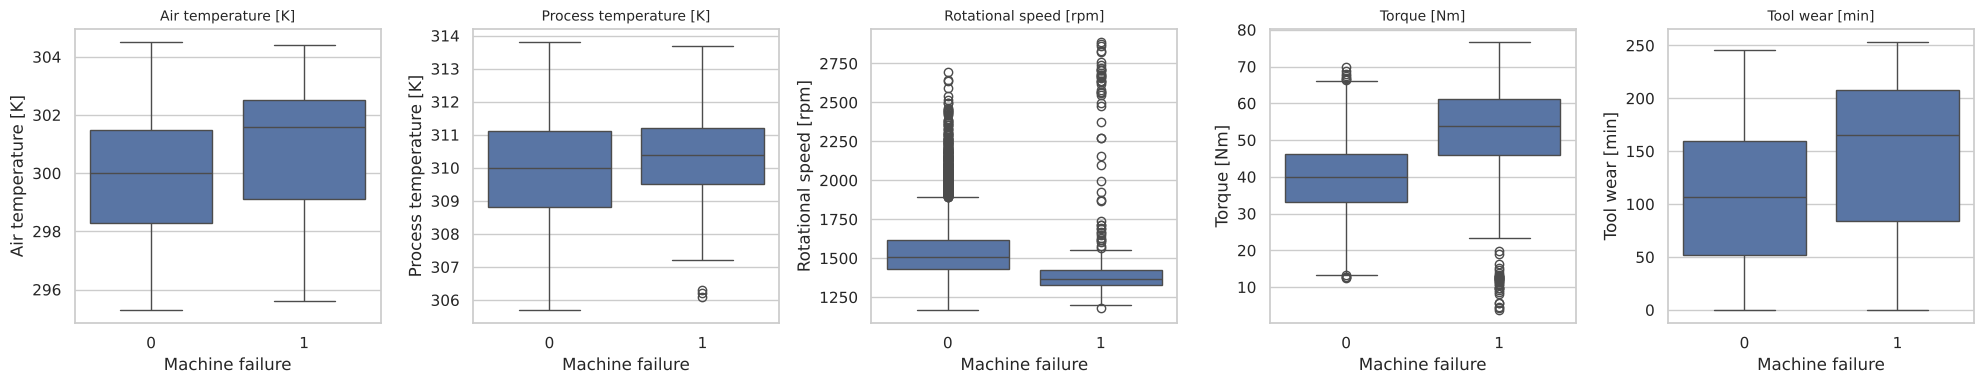

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

In [12]:
df.groupby(TARGET)[NUM_COLS].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


- **Torque** and **tool wear** are clearly higher for failures.
- **Rotational speed** shows failures at both extremes (very low and very high speed), so the relationship is non-linear.
- Temperatures differ only slightly on their own.
- Rotational speed and torque have long tails, so features are standardized before modeling.

## 7. Correlation

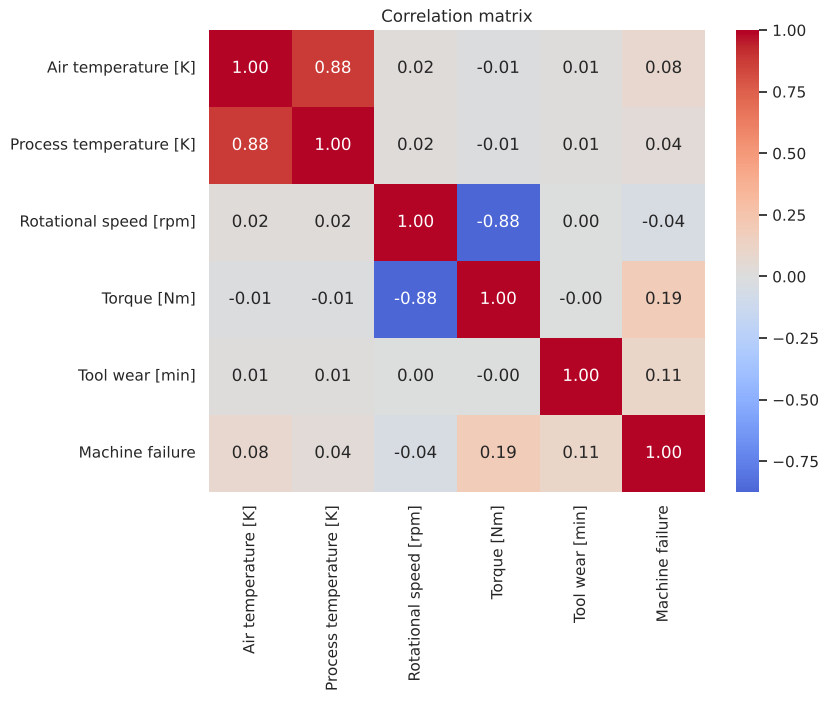

In [13]:
corr_cols = NUM_COLS + [TARGET]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

- Air and process temperature are strongly correlated (r ≈ 0.88).
- Rotational speed and torque are strongly negatively correlated (r ≈ -0.88), which matches machine physics: at roughly constant power, higher speed means lower torque.
- Linear correlations with the target are weak, which suggests that failures depend on **combinations** of features. Correlation does not imply causation.

## 8. Feature interactions

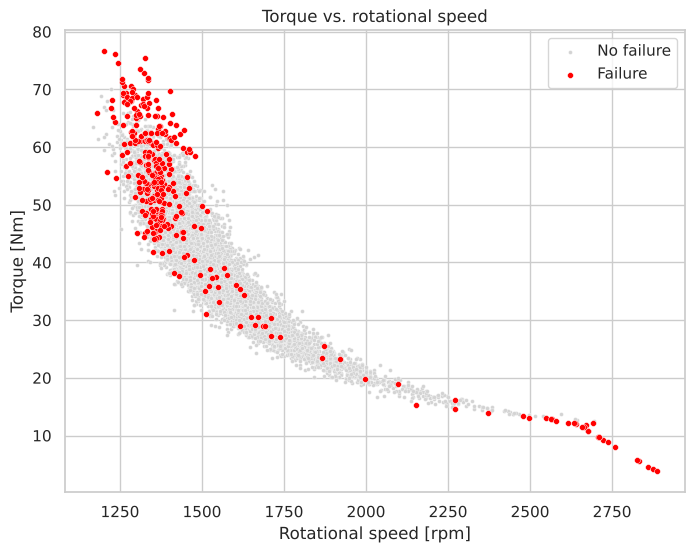

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df[df[TARGET] == 0], x="Rotational speed [rpm]", y="Torque [Nm]",
                color="lightgray", s=8, label="No failure", ax=ax)
sns.scatterplot(data=df[df[TARGET] == 1], x="Rotational speed [rpm]", y="Torque [Nm]",
                color="red", s=18, label="Failure", ax=ax)
ax.set_title("Torque vs. rotational speed")
plt.show()

Failures cluster at the edges of the speed–torque curve: high torque with low speed, and low torque with high speed. These regions correspond to power failure (PWF) and overstrain (OSF).

## 9. Engineered features
Based on how each failure mode is defined, three physics-based features are checked:
- `temp_diff` = process temperature − air temperature → heat dissipation failure (HDF)
- `power` = torque × angular velocity [W] → power failure (PWF)
- `strain` = tool wear × torque → overstrain failure (OSF)

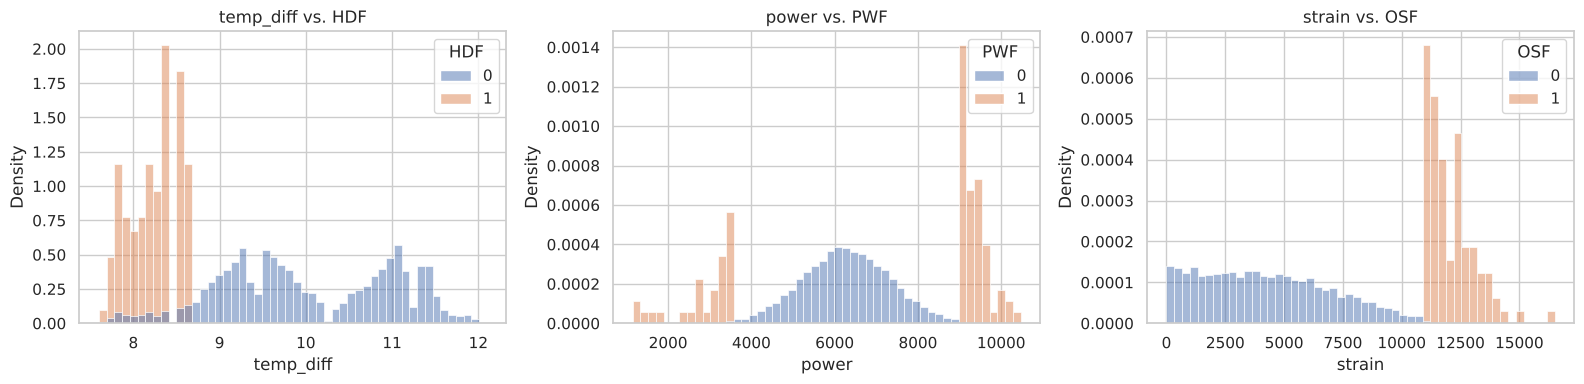

In [15]:
fe = df.copy()
fe["temp_diff"] = fe["Process temperature [K]"] - fe["Air temperature [K]"]
fe["power"] = fe["Torque [Nm]"] * fe["Rotational speed [rpm]"] * 2 * np.pi / 60
fe["strain"] = fe["Tool wear [min]"] * fe["Torque [Nm]"]

eng = ["temp_diff", "power", "strain"]
related_mode = {"temp_diff": "HDF", "power": "PWF", "strain": "OSF"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, eng):
    mode = related_mode[col]
    sns.histplot(data=fe, x=col, hue=mode, stat="density", common_norm=False, bins=50, ax=ax)
    ax.set_title(f"{col} vs. {mode}")
plt.tight_layout()
plt.show()

In [16]:
fe[eng + [TARGET]].corr()[TARGET].drop(TARGET).to_frame("corr with target")

,corr with target
temp_diff,-0.111676
power,0.176039
strain,0.190427


Each engineered feature separates its related failure mode much more clearly than the raw features:
- HDF occurs when `temp_diff` is low.
- PWF occurs when `power` is very low or very high.
- OSF occurs when `strain` is high.

This supports using `ADD_FEATURES = True` in `preprocess.py`, unless the paper we reproduce uses only the original features.

## 10. Failure rate by tool wear

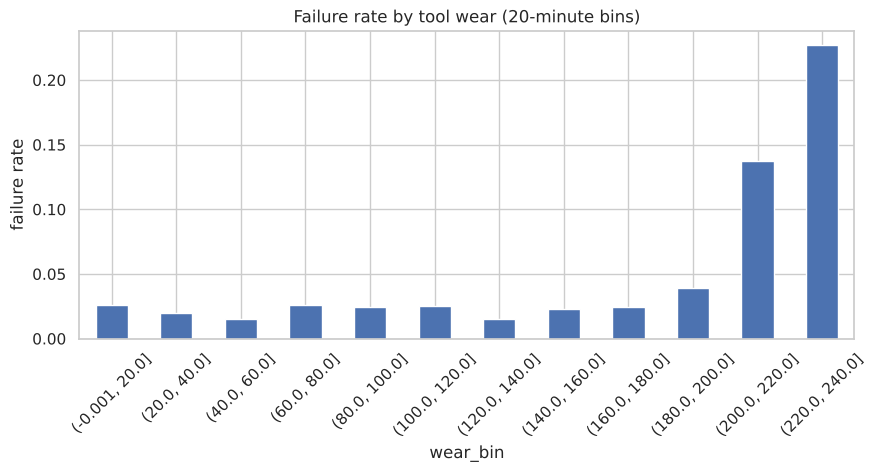

In [17]:
fe["wear_bin"] = pd.cut(fe["Tool wear [min]"], bins=range(0, 260, 20), include_lowest=True)
wear_rate = fe.groupby("wear_bin", observed=True)[TARGET].mean()
fig, ax = plt.subplots(figsize=(10, 4))
wear_rate.plot(kind="bar", ax=ax)
ax.set_ylabel("failure rate")
ax.set_title("Failure rate by tool wear (20-minute bins)")
plt.xticks(rotation=45)
plt.show()

The failure rate rises sharply after about 200 minutes of tool wear, which matches the tool wear failure (TWF) definition.

## 11. Summary → preprocessing decisions

| Finding | Decision in `preprocess.py` |
|---|---|
| `UDI`, `Product ID` are identifiers | Drop |
| `TWF`–`RNF` define the target | Drop (prevents leakage) |
| `Type` is ordered L < M < H | Ordinal encode 0 / 1 / 2 |
| No missing values or duplicates | No imputation needed |
| 27 label-inconsistent rows | Kept for now; team decision |
| Only 3.4% failures | Stratified split; F1 / recall / PR-AUC; resample training data only |
| Features on different scales | StandardScaler fit on train only |
| Failures depend on feature combinations | Add `temp_diff`, `power`, `strain` |